# 2 · Growth analytics: who drives retention and lifetime value?

All aggregation happens in **SQL** (`sql/`) on a modelled analytics layer:

```
raw tables            marts (sql/00_build_marts.sql)
users ─────────┐      fct_transactions   successful txns + tenure columns
transactions ──┼──►   fct_user_months    one row per user per active month
experiments ───┘      user_metrics       one row per user: lifecycle + value
```

Python handles modelling (CLV projection, logistic regression) and charts.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
from upi import config, db, plots
from upi import growth
con = db.connect()
if not db.marts_exist(con): db.build_marts(con)

## Monthly KPIs

In [2]:
print(db.load_sql('01_monthly_kpis.sql'))

-- Monthly platform KPIs: acquisition, MAU, volume, revenue and growth rates.
WITH signups AS (
    SELECT cohort_month AS month, COUNT(*) AS new_users
    FROM user_metrics
    GROUP BY 1
),
activity AS (
    SELECT
        txn_month               AS month,
        COUNT(DISTINCT user_id) AS mau,
        COUNT(*)                AS transactions,
        SUM(amount)             AS gmv,
        SUM(revenue)            AS revenue
    FROM fct_transactions
    GROUP BY 1
)
SELECT
    s.month,
    s.new_users,
    SUM(s.new_users) OVER (ORDER BY s.month)                         AS cumulative_users,
    a.mau,
    a.transactions,
    ROUND(a.gmv, 0)                                                  AS gmv,
    ROUND(a.revenue, 0)                                              AS revenue,
    ROUND(a.gmv / a.transactions, 1)                                 AS avg_txn_value,
    ROUND(1.0 * a.transactions / a.mau, 2)                           AS txns_per_mau,
    ROUND(a.revenue / a.mau, 2)      

In [3]:
kpis = db.query(con, "01_monthly_kpis.sql")
kpis

,month,new_users,cumulative_users,mau,transactions,gmv,revenue,avg_txn_value,txns_per_mau,arpu,mau_growth_pct
0,2024-01,2641,2641,1731,5707,3635675.0,4532.0,637.1,3.30,2.62,NaN
1,2024-02,2937,5578,3372,13284,8553472.0,10346.0,643.9,3.94,3.07,94.8
2,2024-03,3134,8712,4853,20357,12847941.0,15705.0,631.1,4.19,3.24,43.9
3,2024-04,3506,12218,6073,26835,17155290.0,21071.0,639.3,4.42,3.47,25.1
4,2024-05,3863,16081,7563,34045,21860037.0,26467.0,642.1,4.50,3.50,24.5
5,2024-06,6621,22702,10432,45847,29480420.0,35945.0,643.0,4.39,3.45,37.9
6,2024-07,4487,27189,11653,54184,34964856.0,42175.0,645.3,4.65,3.62,11.7
7,2024-08,4656,31845,12521,59942,38072166.0,46580.0,635.2,4.79,3.72,7.4
8,2024-09,5066,36911,13549,65173,41976744.0,50859.0,644.1,4.81,3.75,8.2
9,2024-10,5310,42221,14873,72260,46777722.0,56674.0,647.4,4.86,3.81,9.8


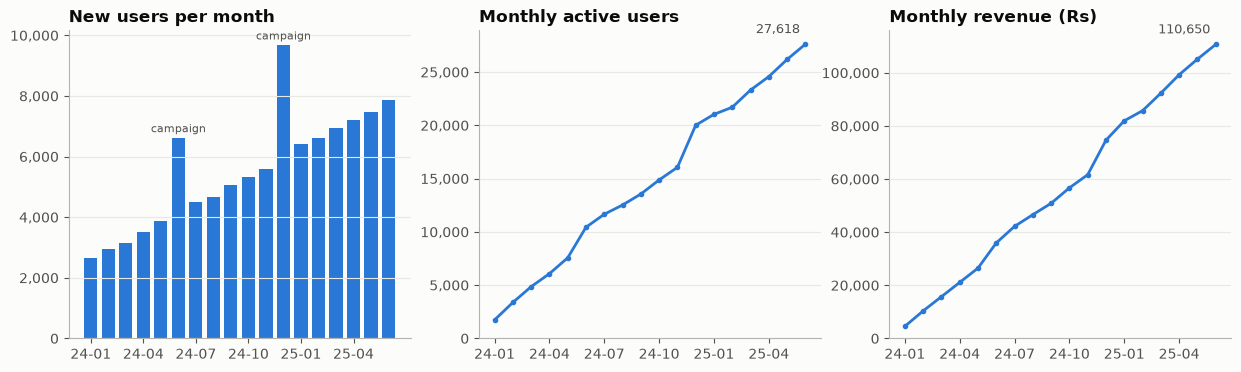

In [4]:
plots.growth_overview(kpis);

In [5]:
stick = db.query(con, "02_stickiness.sql")
stick.tail(6)

,month,avg_dau,mau,stickiness
12,2025-01,3027.0,21030,0.1439
13,2025-02,3473.0,21698,0.1601
14,2025-03,3401.0,23314,0.1459
15,2025-04,3759.0,24574,0.1530
16,2025-05,3869.0,26185,0.1478
17,2025-06,4212.0,27618,0.1525


## Cohort retention

Retention = share of a signup cohort with ≥1 successful transaction in month *k*. Cohorts are remarkably stable,
so retention is a property of the product, not of when users joined.

In [6]:
print(db.load_sql('03_cohort_retention.sql'))

-- Monthly cohort retention triangle.
-- retention = users with >= 1 successful transaction in month k / users who signed up in the cohort.
WITH cohort_size AS (
    SELECT cohort_month, COUNT(*) AS cohort_size
    FROM user_metrics
    GROUP BY 1
)
SELECT
    um.cohort_month,
    fum.months_since_signup,
    COUNT(*)                                   AS active_users,
    cs.cohort_size,
    ROUND(1.0 * COUNT(*) / cs.cohort_size, 4)  AS retention
FROM fct_user_months fum
JOIN user_metrics um USING (user_id)
JOIN cohort_size cs USING (cohort_month)
GROUP BY um.cohort_month, fum.months_since_signup
ORDER BY um.cohort_month, fum.months_since_signup;



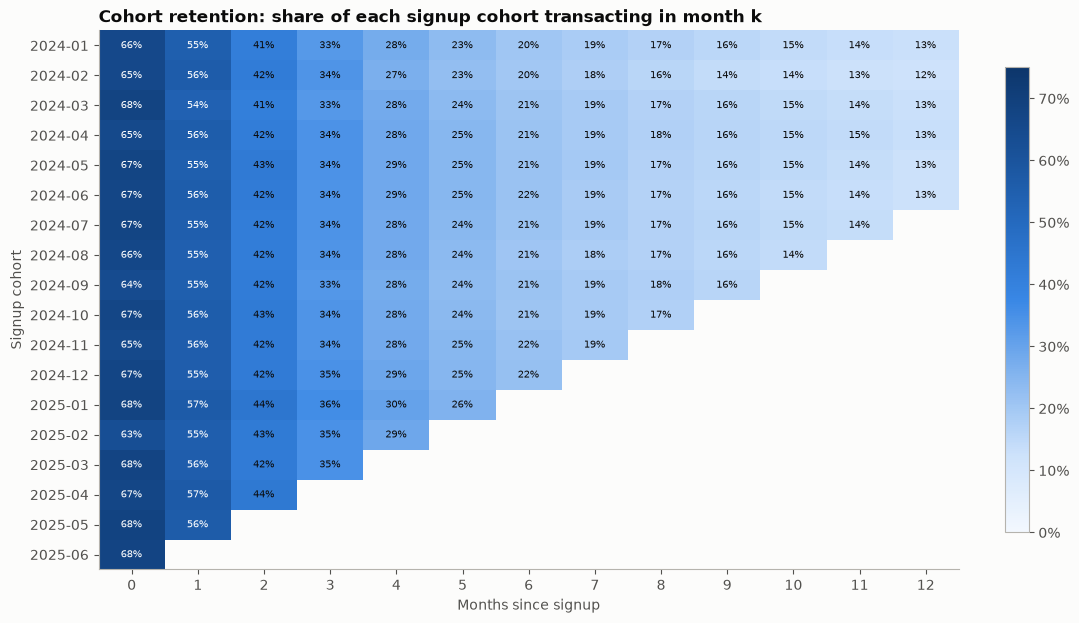

In [7]:
plots.cohort_heatmap(growth.cohort_matrix(con));

## The onboarding funnel

Steps are nested, and only users with 60+ days of history are counted, so every step is fully observable.

,step,users,pct_of_signups,step_conversion
0,Signed up,84929,1.000000,NaN
1,Completed KYC,70825,0.833932,0.833932
2,First transaction,64659,0.761330,0.912940
3,Merchant payment in week 1,23885,0.281235,0.369399
4,...and still active on days 30-60,19104,0.224941,0.799833


,channel,Completed KYC,First transaction,Merchant payment in week 1,...and still active on days 30-60
0,organic,0.833817,0.761110,0.278615,0.219040
1,paid,0.835172,0.729168,0.239613,0.180508
2,referral,0.832917,0.794069,0.328273,0.281363


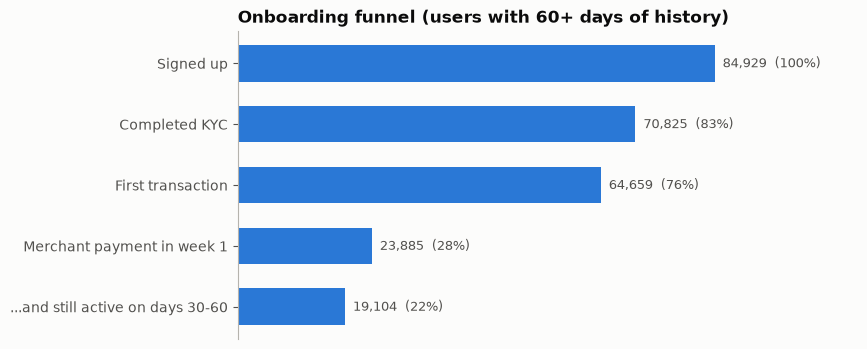

In [8]:
funnel, by_channel = growth.funnel(con)
display(funnel); display(by_channel)
plots.funnel(funnel);

## The 'aha moment': a merchant payment in week 1

The retention curve query only counts a user towards month *k* if they are old enough to have been observed at
month *k*. Without this, recent cohorts would drag the curve down (right-censoring).

In [9]:
print(db.load_sql('05_retention_curve.sql', segment='activated_d7', max_month=12))

-- Retention curve by segment: share of KYC-completed users active k months after signup.
-- A user only counts towards month k if they are old enough to have been observed then,
-- so recent cohorts don't drag the curve down (right-censoring).
-- activated_d7 is substituted from a whitelist in Python (upi.db.SEGMENTS).
WITH RECURSIVE k(m) AS (
    SELECT 0 UNION ALL SELECT m + 1 FROM k WHERE m < 12
),
eligible AS (
    SELECT k.m AS months_since_signup, um.user_id, um.activated_d7 AS segment
    FROM user_metrics um
    JOIN k ON um.months_observed >= k.m
    WHERE um.kyc_completed = 1
)
SELECT
    e.segment,
    e.months_since_signup,
    COUNT(*)                                        AS eligible_users,
    COUNT(f.user_id)                                AS active_users,
    ROUND(1.0 * COUNT(f.user_id) / COUNT(*), 4)     AS retention
FROM eligible e
LEFT JOIN fct_user_months f
       ON f.user_id = e.user_id
      AND f.months_since_signup = e.months_since_signup
GROUP BY e.segment

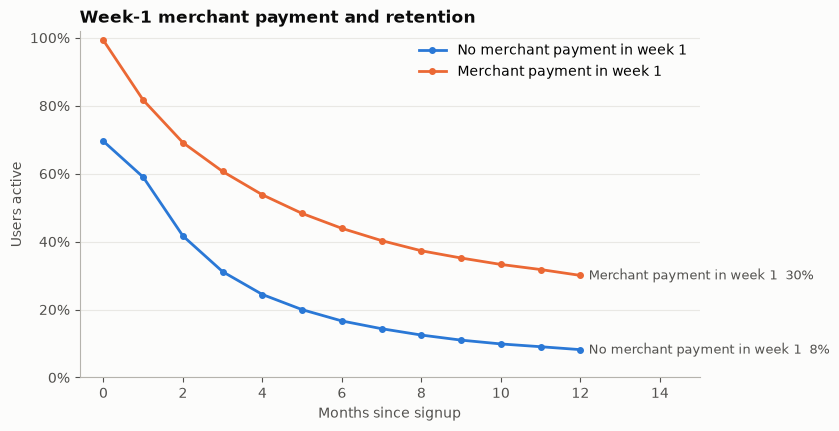

In [10]:
curves = growth.retention_curves(con, "activated_d7")
plots.retention_curves(curves, "Week-1 merchant payment and retention",
                       {0: "No merchant payment in week 1", 1: "Merchant payment in week 1"});

Is that just because engaged users both activate *and* retain? Control for user mix with a logistic regression:

In [11]:
um = pd.read_sql_query("SELECT * FROM user_metrics", con)
impact = growth.activation_impact(um)
print(f"Raw day 30-60 retention: {impact['retention_not_activated']:.1%} -> {impact['retention_activated']:.1%}")
impact["odds_ratios"].round(3)

Raw day 30-60 retention: 55.8% -> 80.0%


,odds_ratio,ci_low,ci_high,p_value
C(channel)[T.paid],0.808,0.778,0.839,0.000
C(channel)[T.referral],1.703,1.635,1.775,0.000
C(city_tier)[T.2],0.844,0.813,0.875,0.000
C(city_tier)[T.3],0.718,0.689,0.749,0.000
C(device)[T.ios],1.017,0.972,1.063,0.468
C(age_group)[T.25-34],0.985,0.947,1.023,0.428
C(age_group)[T.35-44],1.016,0.970,1.064,0.496
C(age_group)[T.45+],0.991,0.935,1.051,0.769
activated_d7,3.039,2.929,3.153,0.000


Activation keeps a ~3x odds ratio after controls. Device and age come out non-significant, which matches the
simulation (no effect was planted there). Still observational: the cashback A/B test in notebook 3 tests the causal
lever.

## Which channel brings valuable users? CLV

$$\text{CLV}_{24m} = \sum_{k=0}^{23} r_k \cdot \text{ARPAU} \cdot (1.01)^{-k}$$

$r_k$ = observed retention (months 0-12), extended by the decay of months 9-12; ARPAU = revenue per active user-month.

,segment,m1_retention,m6_retention,m12_retention,revenue_per_active_month,clv_24m,clv_24m_per_signup
0,referral,0.761,0.363,0.240,4.656,32.734,27.287
1,organic,0.653,0.234,0.136,3.645,17.543,14.641
2,paid,0.598,0.193,0.102,3.006,12.040,10.052


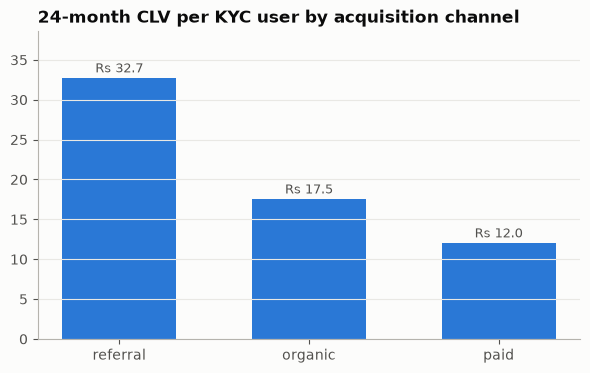

In [12]:
clv = growth.clv_by_segment(con, "channel")
display(clv.round(3))
plots.bar_by_segment(clv, "segment", "clv_24m", "24-month CLV per KYC user by acquisition channel");

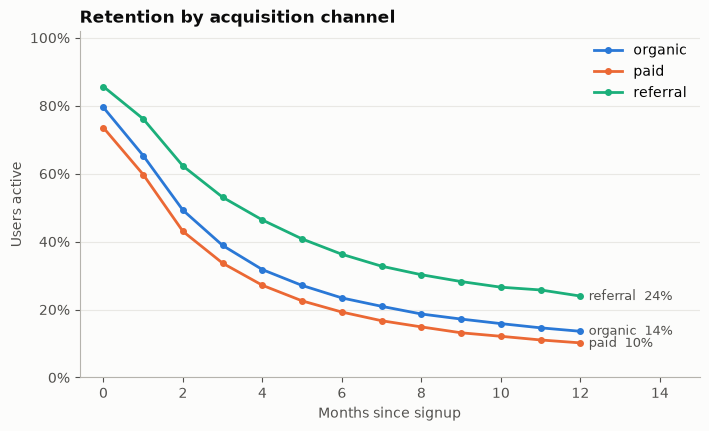

In [13]:
plots.retention_curves(growth.retention_curves(con, 'channel'), 'Retention by acquisition channel');

## Segmentation: RFM and revenue concentration

In [14]:
users_rfm, rfm = growth.rfm_segments(um)
rfm.round(3)

,rfm_segment,users,avg_recency_days,avg_txns,avg_revenue,share_of_users,share_of_revenue
0,Champions,17883,6.664,44.529,34.907,0.237,0.611
1,At risk,13651,277.116,16.667,12.905,0.181,0.172
2,Loyal,13768,58.007,15.204,11.825,0.182,0.159
3,Needs attention,6753,88.547,2.577,1.960,0.089,0.013
4,Hibernating,16550,303.395,2.549,1.946,0.219,0.032
5,New / promising,6898,10.299,2.435,1.872,0.091,0.013


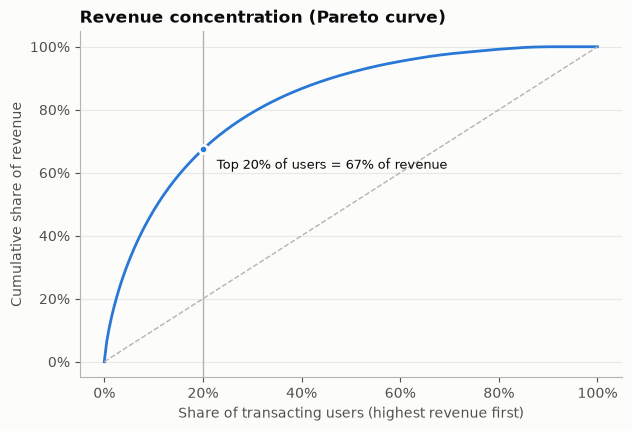

In [15]:
curve, top20 = growth.pareto(um)
plots.pareto(curve, top20);

## Takeaways

1. **Activation is the lever.** Make the first merchant payment the onboarding goal.
2. **Referral users are worth ~2.7x paid users** over 24 months. Shift budget, and reward referrals on activation.
3. **Champions (~24% of users) generate ~61% of revenue.** Protect them; run win-back for *At risk* users.
4. **Tier-3 cities lose users at KYC.** Try vernacular or assisted KYC.

The full write-up is in `reports/growth_report.md`.